In [1]:
from code_utils import *

In [ ]:
K = 100 			# Strike price
sigma = 0.3 		# Volatility 
r = 0.05 		    # Risk-free rate
q = 0 				# Dividend yield
mu = r - q  		# Drift 
T = 0.2  			# Maturity 
dt = 0.004  		# Time step 
N = int(T / dt)  	# Number of steps 

seed = 42 # Random seed for reproducibility
seed_weights = 12345 # Random seed for the weights of the random basis functions

npaths_train= 10**5 # Number of paths for estimating the coefficients of the regression 
npaths_pricing = 10**5 # Number of paths for estimating the price of the option

nneurons = 8 # Number of neurons in the neural network
sigma_basis = 0.11 # Standard deviation for the random basis functions

real_prices = np.array([40.00000000, 39.00000000, 38.00000000, 37.00000000, 36.00000000, 35.00000000, 34.00000000, 33.00000000, 32.00000000, 31.00000000,
			 			30.00000000, 29.00000000, 28.00000000, 27.00000000, 26.00000000, 25.00000000, 24.00000000, 23.00000000, 22.00000000, 21.00000000,
						20.00070685, 19.01347004, 18.04313091, 17.09109638, 16.15883366, 15.24783858, 14.35960625, 13.49560169, 12.65723381, 11.84582143,
						11.06257234, 10.30856320, 9.58471980, 8.89180771, 8.23041673, 7.60094690, 7.00361025, 6.43844700, 5.90532237, 5.40390521,
						4.93370425, 4.49410547, 4.08432251, 3.70344748, 3.35050142, 3.02435964, 2.72386986, 2.44779995, 2.19486933, 1.96380311,
						1.75326609, 1.56197956, 1.38862261, 1.23195119, 1.09070376, 0.96370545, 0.84978944, 0.74786820, 0.65689777, 0.57588855,
						0.50392803, 0.44013960, 0.38373063, 0.33395543, 0.29012326, 0.25161274, 0.21784490, 0.18829301, 0.16248633, 0.13999277,
						0.12042199, 0.10342780, 0.08869869, 0.07595400, 0.06494518, 0.05545341, 0.04728321, 0.04026147, 0.03423616, 0.02907429,0.02465918 ])


# Paths simulation 
train_set = simulate_gbm(mu, sigma, T, dt, npaths_train, seed=seed)
test_set = simulate_gbm( mu, sigma, T, dt, npaths_pricing, seed = seed + 1)

# Applying transformation
stats = fit_log_standardizer(train_set)          
train_log = apply_log_standardizer(train_set, stats)
test_log = apply_log_standardizer(test_set,  stats) 
# Discount factors for each time step
discount_factors = np.exp(-r * np.arange(0, N + 1) * dt) 

# Precomputing the basis for the regression since after transformation the input doesn't depend on S0
basis_train = np.ones((N-1,npaths_train, nneurons + 1))	
basis_pricing = np.ones((N-1, npaths_pricing, nneurons + 1))
# Sigma in this case represents the standard deviation of the random weights 
basis_train_mod, weights_train = random_basis(train_log[1:N,:], nneurons, sigma_basis, seed_weights)
basis_pricing_mod, _ = random_basis(test_log[1:N,:], nneurons, sigma_basis, seed_weights, weights=weights_train)

basis_train = basis_train_mod.transpose(1, 2, 0)
basis_pricing = basis_pricing_mod.transpose(1, 2, 0)
#coeffs_train_dict = {}
#contin_val_train_dict = {}
#value_train_dict = {}

prices = np.empty(81)
uncertainty = np.empty(81)
percentage_error = np.empty(81)

for S0 in np.arange(60,141):
	prices[S0-60], uncertainty[S0-60], _, _, _ , _= lower_bound_ls(K, S0, T, dt, train_set, test_set, discount_factors, npaths_train, npaths_pricing, nneurons - 1, basis_train, basis_pricing)
	# Printing the percentage error wrt the real price
	percentage_error[S0-60] = np.abs(prices[S0-60] - real_prices[S0 - 60]) / real_prices[S0 - 60] * 100
	print(f"S0= {S0}, Estimated Price: {prices[S0-60]:.5f}, Real Price: {real_prices[S0-60]:.5f}, Percentage Error: {percentage_error[S0-60]:.2f}%, Uncertainty: {uncertainty[S0-60]:.5f}")


S0= 60, Estimated Price: 40.00000, Real Price: 40.00000, Percentage Error: 0.00%, Uncertainty: 0.00041
S0= 61, Estimated Price: 39.00000, Real Price: 39.00000, Percentage Error: 0.00%, Uncertainty: 0.00042
S0= 62, Estimated Price: 38.00000, Real Price: 38.00000, Percentage Error: 0.00%, Uncertainty: 0.00043
S0= 63, Estimated Price: 37.00000, Real Price: 37.00000, Percentage Error: 0.00%, Uncertainty: 0.00043
S0= 64, Estimated Price: 36.00000, Real Price: 36.00000, Percentage Error: 0.00%, Uncertainty: 0.00045
S0= 65, Estimated Price: 35.00000, Real Price: 35.00000, Percentage Error: 0.00%, Uncertainty: 0.00047
S0= 66, Estimated Price: 34.00000, Real Price: 34.00000, Percentage Error: 0.00%, Uncertainty: 0.00050
S0= 67, Estimated Price: 33.00000, Real Price: 33.00000, Percentage Error: 0.00%, Uncertainty: 0.00049
S0= 68, Estimated Price: 32.00000, Real Price: 32.00000, Percentage Error: 0.00%, Uncertainty: 0.00053
S0= 69, Estimated Price: 31.00000, Real Price: 31.00000, Percentage Error

In [5]:
np.savez('rnn_av_ls_results.npz', S0=np.arange(60,141), price=prices, error=percentage_error, uncertainty=uncertainty)

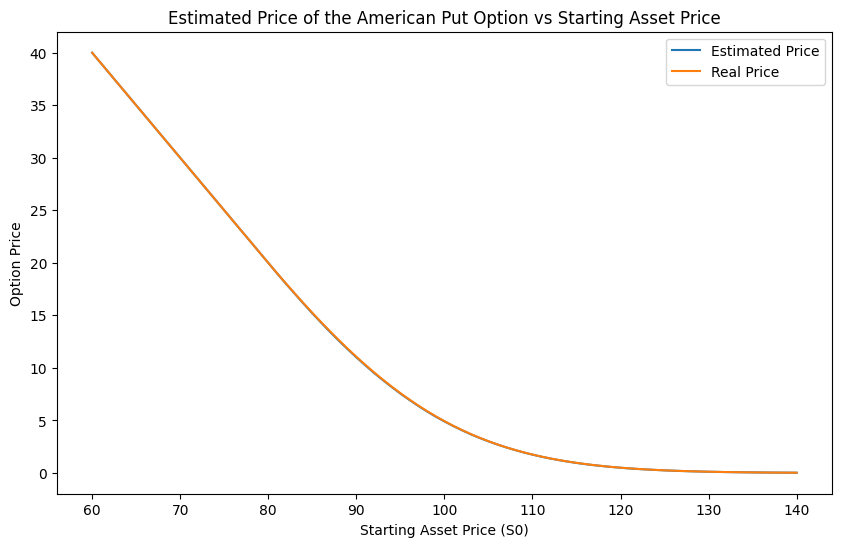

In [6]:
# Plot of the price of the option wrt the starting value of the asset
plt.figure(figsize = (10,6))
plt.plot(np.arange(60,141), prices, label='Estimated Price')
plt.plot(np.arange(60,141), real_prices, label='Real Price')
plt.title('Estimated Price of the American Put Option vs Starting Asset Price')
plt.xlabel('Starting Asset Price (S0)')
plt.ylabel('Option Price')
plt.legend()

In [2]:
K = 100 			# Strike price
sigma = 0.3 		# Volatility 
r = 0.05 		    # Risk-free rate
q = 0 				# Dividend yield
mu = r - q  		# Drift 
T = 0.2  			# Maturity 
dt = 0.004  		# Time step 
N = int(T / dt)  	# Number of steps 

seed = 42 # Random seed for reproducibility
seed_weights = 12345 # Random seed for the weights of the random basis functions

npaths_train= 10**5 # Number of paths for estimating the coefficients of the regression 
npaths_pricing = 10**5 # Number of paths for estimating the price of the option

nneurons = 8 # Number of neurons in the neural network
sigma_basis = 0.11 # Standard deviation for the random basis functions 

real_prices = np.array([40.00000000, 39.00000000, 38.00000000, 37.00000000, 36.00000000, 35.00000000, 34.00000000, 33.00000000, 32.00000000, 31.00000000,
			 			30.00000000, 29.00000000, 28.00000000, 27.00000000, 26.00000000, 25.00000000, 24.00000000, 23.00000000, 22.00000000, 21.00000000,
						20.00070685, 19.01347004, 18.04313091, 17.09109638, 16.15883366, 15.24783858, 14.35960625, 13.49560169, 12.65723381, 11.84582143,
						11.06257234, 10.30856320, 9.58471980, 8.89180771, 8.23041673, 7.60094690, 7.00361025, 6.43844700, 5.90532237, 5.40390521,
						4.93370425, 4.49410547, 4.08432251, 3.70344748, 3.35050142, 3.02435964, 2.72386986, 2.44779995, 2.19486933, 1.96380311,
						1.75326609, 1.56197956, 1.38862261, 1.23195119, 1.09070376, 0.96370545, 0.84978944, 0.74786820, 0.65689777, 0.57588855,
						0.50392803, 0.44013960, 0.38373063, 0.33395543, 0.29012326, 0.25161274, 0.21784490, 0.18829301, 0.16248633, 0.13999277,
						0.12042199, 0.10342780, 0.08869869, 0.07595400, 0.06494518, 0.05545341, 0.04728321, 0.04026147, 0.03423616, 0.02907429,0.02465918 ])


for S0 in np.arange(60,141):
	price_estimate, uncertainty_estimate = rnn_lower_bound_american_put_ls(K, S0, T, dt, r, q, sigma, seed, npaths_train, npaths_pricing, nneurons - 1, sigma_basis, seed_weights)
	# Printing the percentage error wrt the real price
	percentage_error = np.abs(price_estimate - real_prices[S0 - 60]) / real_prices[S0 - 60] * 100
	print(f"S0= {S0}, Estimated Price: {price_estimate:.5f}, Real Price: {real_prices[S0-60]:.5f}, Percentage Error: {percentage_error:.2f}%, Uncertainty: {uncertainty_estimate:.5f}")

S0= 60, Estimated Price: 40.00000, Real Price: 40.00000, Percentage Error: 0.00%, Uncertainty: 0.00039
S0= 61, Estimated Price: 39.00000, Real Price: 39.00000, Percentage Error: 0.00%, Uncertainty: 0.00040
S0= 62, Estimated Price: 38.00000, Real Price: 38.00000, Percentage Error: 0.00%, Uncertainty: 0.00041
S0= 63, Estimated Price: 37.00000, Real Price: 37.00000, Percentage Error: 0.00%, Uncertainty: 0.00043
S0= 64, Estimated Price: 36.00000, Real Price: 36.00000, Percentage Error: 0.00%, Uncertainty: 0.00043
S0= 65, Estimated Price: 35.00000, Real Price: 35.00000, Percentage Error: 0.00%, Uncertainty: 0.00044
S0= 66, Estimated Price: 34.00000, Real Price: 34.00000, Percentage Error: 0.00%, Uncertainty: 0.00045
S0= 67, Estimated Price: 33.00000, Real Price: 33.00000, Percentage Error: 0.00%, Uncertainty: 0.00050
S0= 68, Estimated Price: 32.00000, Real Price: 32.00000, Percentage Error: 0.00%, Uncertainty: 0.00047
S0= 69, Estimated Price: 31.00000, Real Price: 31.00000, Percentage Error